# Ligands 47, 41 (fasudil) and 23 docked onto the apo ensemble of a-syn-C-term

Populations of intermolecular interactions and dual residue contact probability for the three published ligands, docked with AutoDock Vina-GPU onto all 20,020 frames of the apo MD simulation. The best box per frame is taken from the extracted score table; frames where fewer than 15 boxes completed are excluded.

These runs used Rg-scaled boxes (47: 16.58 A, 41: 13.01 A, 23: 13.17 A) rather than the uniform 18.75 A box of the other jobs, so their interaction profiles are comparable in shape but the protocols are not identical.

Each frame is the receptor conformation that was docked against, plus the best-of-20
pose (the lowest-scoring of the 20 per-residue boxes). The example notebook reweights
t-SNE clusters by their MD populations; these ensembles are instead stride-sampled from
equilibrium trajectories, so every frame carries equal weight and the ensemble is treated
as a single cluster with weight 1.

Build the input once with
`python build_docked_trajectories.py --job trio_apo`.

In [1]:
import os, sys, json
import numpy as np
import mdtraj as md

for p in ("~/data/scripts", "~/data/scripts/docking_analysis"):
    p = os.path.expanduser(p)
    if os.path.isdir(os.path.join(p, "docking_tools")) and p not in sys.path:
        sys.path.insert(0, p)
from docking_tools import trajectory_analysis
from docking_tools import plotting

In [2]:
JOB = "trio_apo"
DATA = os.path.expanduser(f"~/data/docked_trajectories/{JOB}")
LIGANDS = [47, 41, 23]

# one cluster with weight 1 (uniform, stride-sampled ensemble)
N_CLUS = 1
weights = np.array([1.0])
contacts = {}

In [3]:
def load_docked(lig):
    """Docked trajectory + ligand atom groups written by build_docked_trajectories.py."""
    top = md.load_topology(os.path.join(DATA, f"lig{lig}_top.pdb"))
    traj = md.Trajectory(np.load(os.path.join(DATA, f"lig{lig}_xyz.npy")), top)
    with open(os.path.join(DATA, f"lig{lig}_groups.json")) as fh:
        groups = json.load(fh)
    return traj, groups


def analyse(lig):
    traj, g = load_docked(lig)
    n_frames = traj.n_frames
    # number of residues in the protein; the ligand is the last residue (0 indexed)
    n_res = traj.atom_slice(traj.top.select('protein')).n_residues
    ligand_idx = n_res
    shape = (N_CLUS, n_frames, n_res)
    empty = lambda: np.zeros(shape)

    contacts = {}
    contacts['hphob'] = trajectory_analysis.hphob_contacts(traj, ligand_idx).reshape(shape)
    contacts['aro'] = (trajectory_analysis.aro_contacts(traj, ligand_rings=g['aromatic_rings']).reshape(shape)
                       if g['aromatic_rings'] else empty())
    contacts['hbond'] = (trajectory_analysis.hbond(traj, ligand_idx, lig_hbond_donors=g['hbond_donors']).reshape(shape)
                         if g['hbond_donors'] else empty())
    contacts['charge'] = (trajectory_analysis.charge_contacts(traj, Ligand_Pos_Charges=g['positive_charges']).reshape(shape)
                          if g['positive_charges'] else empty())
    contacts['dual'] = np.array([trajectory_analysis.dual_contact(traj, residue_idx=ligand_idx)])
    print(f"ligand {lig}: {n_frames} frames, {n_res} residues")
    return contacts

## Ligand atom groups

In [4]:
# detected ligand atom groups -- check these against each ligand's chemistry
# before reading the aromatic, H-bond and charge panels
for lig in LIGANDS:
    try:
        with open(os.path.join(DATA, f"lig{lig}_groups.json")) as fh:
            g = json.load(fh)
    except FileNotFoundError:
        print(f"ligand {lig:>3}: not built yet"); continue
    print(f"ligand {lig:>3}: {g['n_frames']:>6} frames | rings {len(g['aromatic_rings'])} "
          f"| donors {len(g['hbond_donors'])} | cation {g['positive_charges']} "
          f"| anion {g['negative_charges']}")

ligand  47:  20020 frames | rings 1 | donors 2 | cation [312] | anion []
ligand  41:  19280 frames | rings 2 | donors 2 | cation [310] | anion []
ligand  23:  19278 frames | rings 2 | donors 1 | cation [] | anion []


## Ligand 47

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 47: 20020 frames, 20 residues


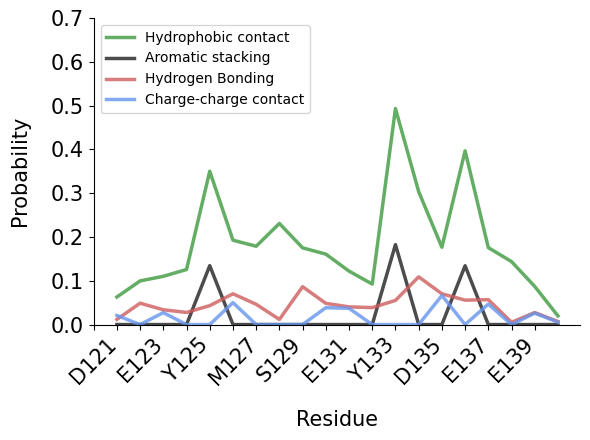

In [5]:
contacts[47] = analyse(47)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[47], weights)

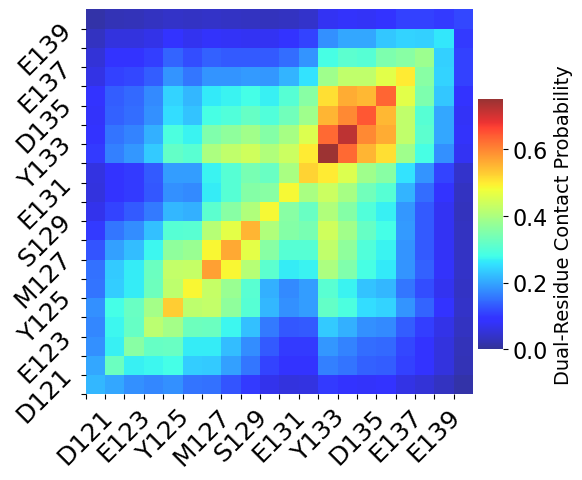

In [6]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[47]['dual'], weights)

## Ligand 41

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 41: 19280 frames, 20 residues


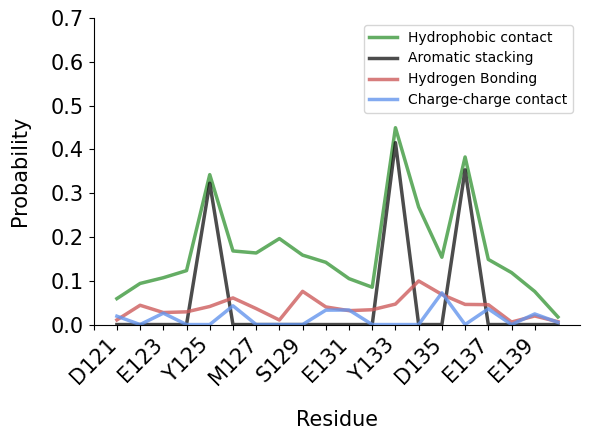

In [7]:
contacts[41] = analyse(41)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[41], weights)

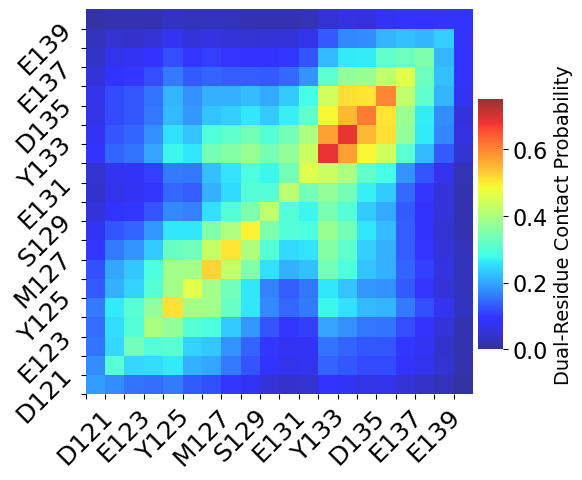

In [8]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[41]['dual'], weights)

## Ligand 23

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 23: 19278 frames, 20 residues


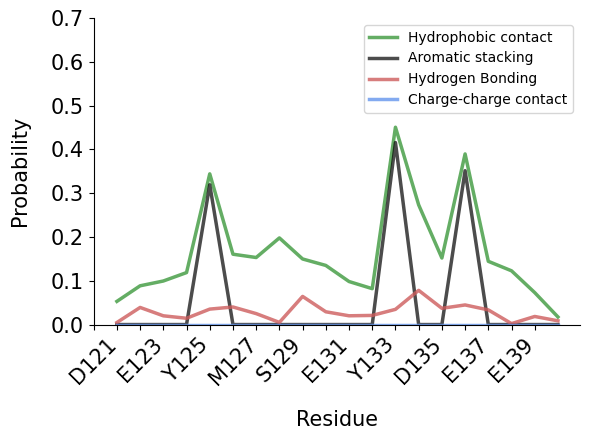

In [9]:
contacts[23] = analyse(23)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[23], weights)

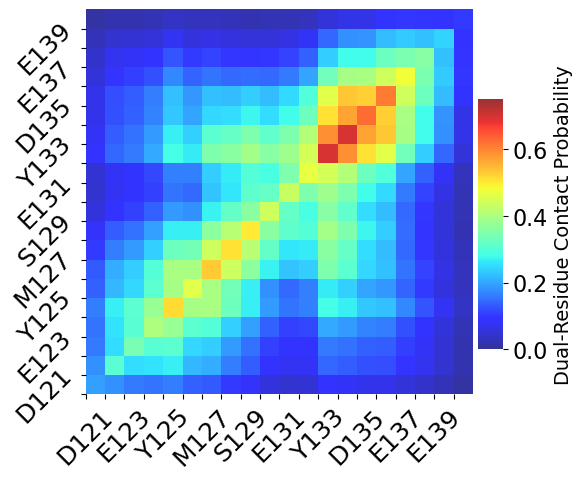

In [10]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[23]['dual'], weights)